In [2]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q -o /content/drive/MyDrive/T3/protocolo_T3_VerificacionLocutor.zip -d /content

Mounted at /content/drive


In [5]:
from huggingface_hub import login, hf_hub_download

login()

ruta = hf_hub_download(repo_id="ProgramComputer/voxceleb",
                       filename="vox1/vox1_test_wav.zip",
                       repo_type="dataset",
                       local_dir="/content")
print(ruta)

vox1/vox1_test_wav.zip: reconstructing file:   0%|          |  0.00B / 1.07GB            

vox1/vox1_test_wav.zip: downloading bytes:           |  0.00B            

/content/vox1/vox1_test_wav.zip


In [6]:
!unzip -q /content/vox1/vox1_test_wav.zip -d /content/vox1
!ls /content/vox1
!find /content/vox1 -name "*.wav" | wc -l
!find /content/vox1 -name "*.wav" | head -3

vox1_test_wav.zip  wav
4874
/content/vox1/wav/id10289/Fvm877eQSqE/00001.wav
/content/vox1/wav/id10289/3g9CjhcNEWk/00005.wav
/content/vox1/wav/id10289/3g9CjhcNEWk/00004.wav


In [7]:
import os
import pandas as pd

BASE = "/content/vox1/wav/"
PROT = "/content/protocolo_vox1/"

pares = pd.read_csv(PROT + "veri_test_original.txt", sep=" ", header=None, names=["label", "audio1", "audio2"])

registro = pd.read_csv(PROT + "enrollment_10.csv")
pruebas  = pd.read_csv(PROT + "probes.csv")
trials   = pd.read_csv(PROT + "trials_registro10.csv")

print("Pares protocolo A:", len(pares))
print("Audios de registro:", len(registro), "| personas:", registro["speaker_id"].nunique())
print("Audios de prueba:", len(pruebas))
print("Comparaciones protocolo B:", len(trials))

print("A ->", pares["label"].value_counts().to_dict())
print("B ->", trials["label"].value_counts().to_dict())

audios = set(pares["audio1"]) | set(pares["audio2"]) | set(registro["audio_path"]) | set(pruebas["audio_path"])
faltan = [a for a in audios if not os.path.exists(BASE + a)]
print("Audios distintos usados:", len(audios))
print("Audios que faltan:", len(faltan))

print(trials.head(4))

Pares protocolo A: 37720
Audios de registro: 400 | personas: 40
Audios de prueba: 4315
Comparaciones protocolo B: 8630
A -> {1: 18860, 0: 18860}
B -> {1: 4315, 0: 4315}
Audios distintos usados: 4715
Audios que faltan: 0
   trial_id  probe_id  label enrollment_speaker_id test_speaker_id  \
0         1         1      1               id10270         id10270   
1         2         1      0               id10272         id10270   
2         3         2      1               id10270         id10270   
3         4         2      0               id10276         id10270   

                      test_audio  
0  id10270/5r0dWxy17C8/00001.wav  
1  id10270/5r0dWxy17C8/00001.wav  
2  id10270/5r0dWxy17C8/00002.wav  
3  id10270/5r0dWxy17C8/00002.wav  


In [8]:
!pip install -q speechbrain

In [17]:
!pip freeze | grep -iE "^(torch|speechbrain|transformers|soundfile|numpy|pandas|matplotlib|tqdm|huggingface.hub)=="

huggingface_hub==1.33.0
matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
soundfile==0.14.0
speechbrain==1.1.2
torch==2.14.1+cu130
tqdm==4.67.3
transformers==5.22.1


In [9]:
import torch
import numpy as np
import soundfile as sf
from speechbrain.inference.speaker import EncoderClassifier

disp = "cuda:0" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", disp)

ecapa = EncoderClassifier.from_hparams(source="speechbrain/spkrec-ecapa-voxceleb",
                                       savedir="/content/modelo_ecapa",
                                       run_opts={"device": disp})

def emb_ecapa(ruta):
    senal, fs = sf.read(BASE + ruta, dtype="float32")
    x = torch.tensor(senal).unsqueeze(0)
    with torch.no_grad():
        e = ecapa.encode_batch(x)
    return e.squeeze().cpu().numpy()

def coseno(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

senal, fs = sf.read(BASE + pares["audio1"][0])
e = emb_ecapa(pares["audio1"][0])
print("fs =", fs, "Hz | duración =", round(len(senal) / fs, 2), "s | embedding:", e.shape)

for i in range(4):
    a1, a2, lab = pares["audio1"][i], pares["audio2"][i], pares["label"][i]
    s = coseno(emb_ecapa(a1), emb_ecapa(a2))
    tipo = "GENUINO " if lab == 1 else "IMPOSTOR"
    print(tipo, "| similitud =", round(float(s), 3), "|", a1, "vs", a2)

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


Dispositivo: cuda:0


hyperparams.yaml:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


embedding_model.ckpt: reconstructing file:   0%|          |  0.00B / 83.3MB            

embedding_model.ckpt: downloading bytes:           |  0.00B            

... (5 outputs left out)

INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


label_encoder.txt:   0%|          | 0.00/129k [00:00<?, ?B/s]

INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


fs = 16000 Hz | duración = 5.68 s | embedding: (192,)
GENUINO  | similitud = 0.586 | id10270/x6uYqmx31kE/00001.wav vs id10270/8jEAjG6SegY/00008.wav
IMPOSTOR | similitud = 0.067 | id10270/x6uYqmx31kE/00001.wav vs id10300/ize_eiCFEg0/00003.wav
GENUINO  | similitud = 0.576 | id10270/x6uYqmx31kE/00001.wav vs id10270/GWXujl-xAVM/00017.wav
IMPOSTOR | similitud = -0.071 | id10270/x6uYqmx31kE/00001.wav vs id10273/0OCW1HUxZyg/00001.wav


In [10]:
import pickle
from tqdm import tqdm

lista = sorted(audios)

emb_E = {}
for ruta in tqdm(lista):
    emb_E[ruta] = emb_ecapa(ruta)

print("Embeddings calculados:", len(emb_E))

with open("/content/drive/MyDrive/T3/emb_ecapa.pkl", "wb") as f:
    pickle.dump(emb_E, f)
print("Guardado en Drive")

100%|██████████| 4715/4715 [01:33<00:00, 50.56it/s]


Embeddings calculados: 4715
Guardado en Drive


In [11]:
from transformers import AutoFeatureExtractor, WavLMForXVector

nombre = "microsoft/wavlm-base-plus-sv"
fe = AutoFeatureExtractor.from_pretrained(nombre)
wavlm = WavLMForXVector.from_pretrained(nombre).to(disp).eval()

def emb_wavlm(ruta):
    senal, fs = sf.read(BASE + ruta, dtype="float32")
    ent = fe(senal, sampling_rate=16000, return_tensors="pt")
    ent = {k: v.to(disp) for k, v in ent.items()}
    with torch.no_grad():
        e = wavlm(**ent).embeddings
    return e.squeeze().cpu().numpy()

print("embedding:", emb_wavlm(pares["audio1"][0]).shape)

for i in range(4):
    a1, a2, lab = pares["audio1"][i], pares["audio2"][i], pares["label"][i]
    s = coseno(emb_wavlm(a1), emb_wavlm(a2))
    tipo = "GENUINO " if lab == 1 else "IMPOSTOR"
    print(tipo, "| similitud =", round(float(s), 3))

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/58.6k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  405MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  404MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/266 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


embedding: (512,)
GENUINO  | similitud = 0.972
IMPOSTOR | similitud = 0.35
GENUINO  | similitud = 0.943
IMPOSTOR | similitud = 0.456


In [12]:
emb_W = {}
for ruta in tqdm(lista):
    emb_W[ruta] = emb_wavlm(ruta)

print("Embeddings calculados:", len(emb_W))

with open("/content/drive/MyDrive/T3/emb_wavlm.pkl", "wb") as f:
    pickle.dump(emb_W, f)
print("Guardado en Drive")

100%|██████████| 4715/4715 [05:13<00:00, 15.02it/s]


Embeddings calculados: 4715
Guardado en Drive


In [13]:
def puntajes_A(emb):
    return np.array([coseno(emb[a], emb[b]) for a, b in zip(pares["audio1"], pares["audio2"])])

def huellas(emb):
    h = {}
    for persona, grupo in registro.groupby("speaker_id"):
        vectores = [emb[r] for r in grupo["audio_path"]]
        h[persona] = np.mean(vectores, axis=0)
    return h

def puntajes_B(emb):
    h = huellas(emb)
    return np.array([coseno(h[p], emb[t]) for p, t in zip(trials["enrollment_speaker_id"], trials["test_audio"])])

yA = pares["label"].values
yB = trials["label"].values

punt = {"ECAPA - A": puntajes_A(emb_E),
        "ECAPA - B": puntajes_B(emb_E),
        "WavLM - A": puntajes_A(emb_W),
        "WavLM - B": puntajes_B(emb_W)}

for nombre, s in punt.items():
    y = yA if nombre.endswith("A") else yB
    print(nombre,  "n =", len(s),
          "genuinos prom =", round(s[y == 1].mean(), 3),
          "impostores prom =", round(s[y == 0].mean(), 3))

with open("/content/drive/MyDrive/T3/puntajes.pkl", "wb") as f:
    pickle.dump(punt, f)

ECAPA - A n = 37720 genuinos prom = 0.592 impostores prom = 0.024
ECAPA - B n = 8630 genuinos prom = 0.707 impostores prom = 0.023
WavLM - A n = 37720 genuinos prom = 0.943 impostores prom = 0.573
WavLM - B n = 8630 genuinos prom = 0.964 impostores prom = 0.586


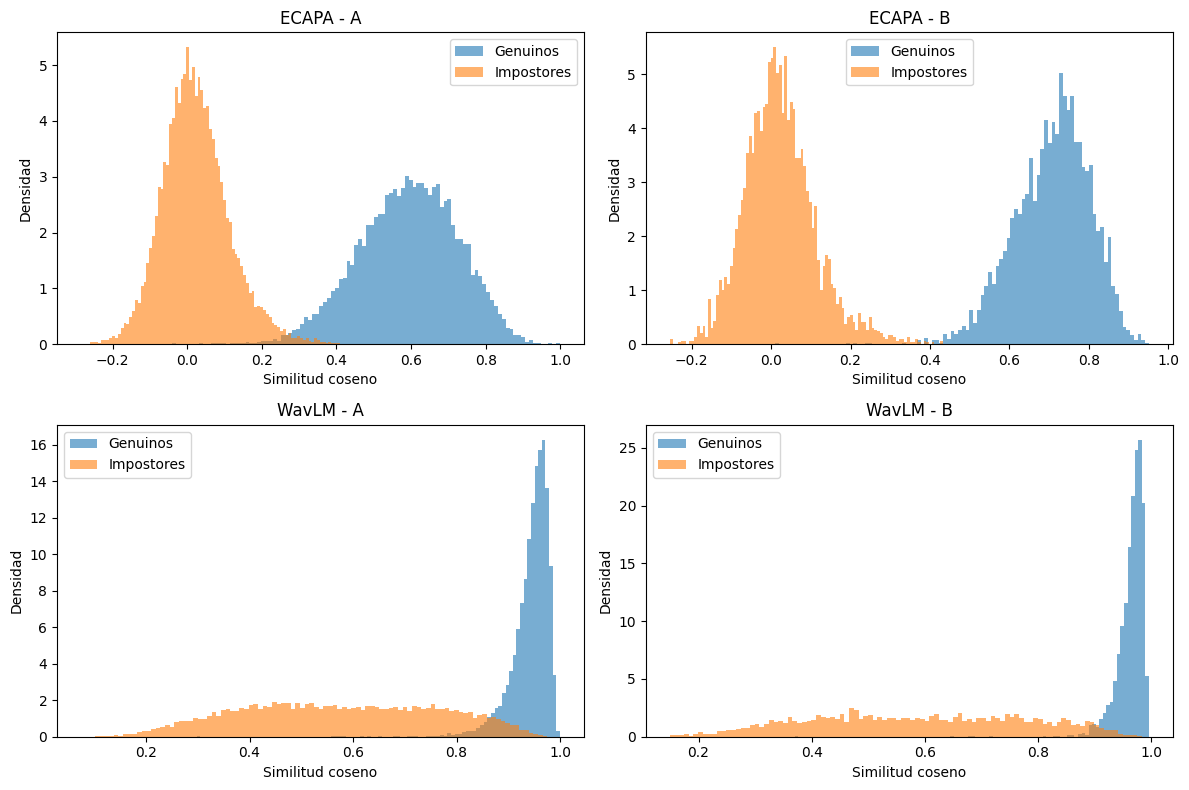

In [14]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(2, 2, figsize=(12, 8))

for eje, (nombre, s) in zip(ejes.flatten(), punt.items()):
    y = yA if nombre.endswith("A") else yB
    eje.hist(s[y == 1], bins=100, density=True, alpha=0.6, label="Genuinos")
    eje.hist(s[y == 0], bins=100, density=True, alpha=0.6, label="Impostores")
    eje.set_title(nombre)
    eje.set_xlabel("Similitud coseno")
    eje.set_ylabel("Densidad")
    eje.legend()

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/T3/histogramas.png", dpi=150)
plt.show()

ECAPA - A | EER = 1.04 % | umbral = 0.272
ECAPA - B | EER = 0.15 % | umbral = 0.369
WavLM - A | EER = 4.83 % | umbral = 0.874
WavLM - B | EER = 2.67 % | umbral = 0.908


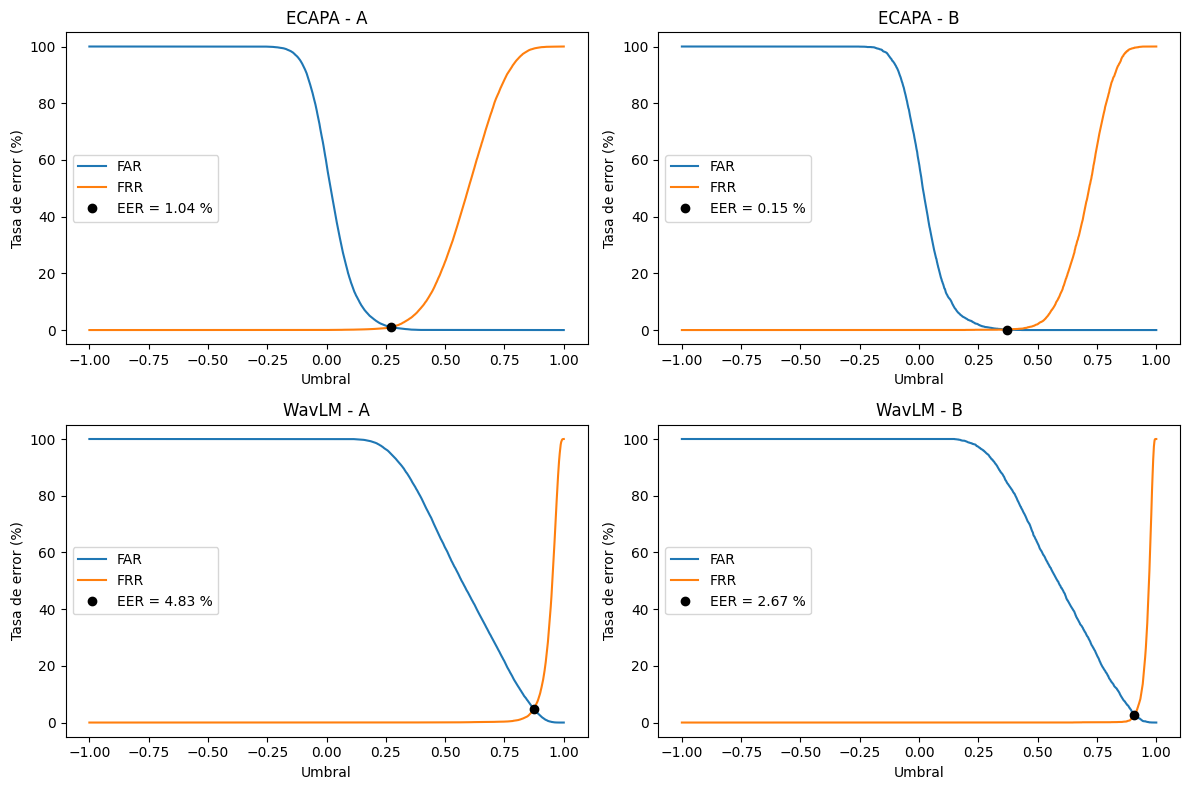

In [15]:
umbrales = np.linspace(-1, 1, 2001)

def far_frr(s, y):
    gen = s[y == 1]
    imp = s[y == 0]
    far = np.array([(imp >= u).mean() for u in umbrales])
    frr = np.array([(gen <  u).mean() for u in umbrales])
    return far, frr

res = {}
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))

for eje, (nombre, s) in zip(ejes.flatten(), punt.items()):
    y = yA if nombre.endswith("A") else yB
    far, frr = far_frr(s, y)
    i = np.argmin(np.abs(far - frr))
    eer = (far[i] + frr[i]) / 2
    res[nombre] = (far, frr, eer, umbrales[i])
    print(nombre, "| EER =", round(100 * eer, 2), "% | umbral =", round(umbrales[i], 3))

    eje.plot(umbrales, 100 * far, label="FAR")
    eje.plot(umbrales, 100 * frr, label="FRR")
    eje.plot(umbrales[i], 100 * eer, "ko", label=f"EER = {100*eer:.2f} %")
    eje.set_title(nombre)
    eje.set_xlabel("Umbral")
    eje.set_ylabel("Tasa de error (%)")
    eje.legend()

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/T3/far_frr.png", dpi=150)
plt.show()

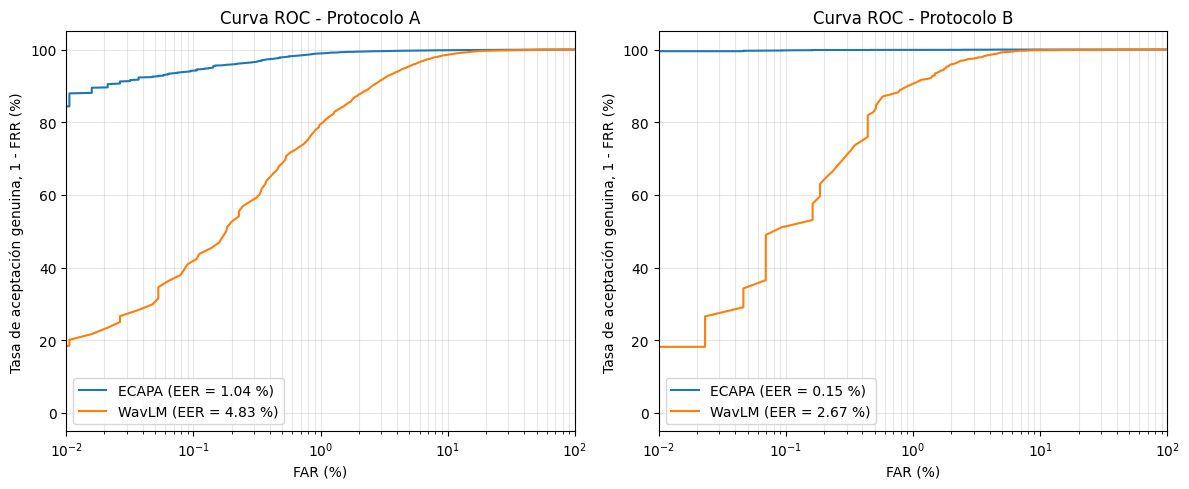

In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

for eje, prot in zip(ejes, ["A", "B"]):
    for modelo in ["ECAPA", "WavLM"]:
        far, frr, eer, u = res[f"{modelo} - {prot}"]
        eje.plot(100 * far, 100 * (1 - frr), label=f"{modelo} (EER = {100*eer:.2f} %)")
    eje.set_xscale("log")
    eje.set_xlim(0.01, 100)
    eje.set_title(f"Curva ROC - Protocolo {prot}")
    eje.set_xlabel("FAR (%)")
    eje.set_ylabel("Tasa de aceptación genuina, 1 - FRR (%)")
    eje.grid(True, which="both", alpha=0.3)
    eje.legend()

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/T3/roc.png", dpi=150)
plt.show()